# Vision — Regresi dari Gambar (tebak angka dari foto)
**Kapan dipakai:** usia dari foto wajah (Satria Data 2021), harga dari foto barang, berat
ternak, luas kerusakan, jumlah orang di keramaian. Target berupa **angka**, bukan kelas.

**Langkah:** tiap gambar diperkecil ke ukuran sama → embedding pretrained beku → regresi
sklearn. Multi-output (mis. usia + gender sekaligus): `y` berisi beberapa kolom, `Ridge`
langsung bisa, model lain dibungkus `MultiOutputRegressor(...)`.

**Data demo:** PennFudan (foto pejalan kaki, ukuran tiap gambar berbeda), target `jumlah` orang.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from lightgbm import LGBMRegressor
from PIL import Image
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from torch import nn
from torchvision import models

## Konfigurasi

In [2]:
DATA_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/regresi"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/pennfudan_train.csv"
TEST_CSV = f"{DATA_FOLDER}/pennfudan_test.csv"
TEST_KEY_CSV = f"{DATA_FOLDER}/pennfudan_test_labels.csv"   # hanya ada di data latihan
IMAGE_FOLDER = "Z:/GEMASTIK-DATABASE/data_latihan/vision/detection/PennFudanPed"
PRETRAINED = "Z:/GEMASTIK-DATABASE/pretrained"

PATH_COL = "path"     # path gambar, relatif terhadap IMAGE_FOLDER
TARGET = "jumlah"
IMAGE_SIZE = 224
BATCH_SIZE = 32
SEED = 42
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"
MEAN = np.array([0.485, 0.456, 0.406])   # normalisasi warna ImageNet
STD = np.array([0.229, 0.224, 0.225])

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| test:", test.shape)
print(train[TARGET].value_counts().sort_index())
train.head()

train: (120, 3) | test: (50, 2)
jumlah
1    41
2    26
3    25
4    12
5     9
6     4
7     2
8     1
Name: count, dtype: int64


,id,path,jumlah
0,0,PNGImages/FudanPed00001.png,2
1,1,PNGImages/FudanPed00002.png,1
2,2,PNGImages/FudanPed00003.png,1
3,3,PNGImages/FudanPed00004.png,2
4,4,PNGImages/FudanPed00005.png,2


## EDA: ukuran gambar dan contoh

PNGImages/FudanPed00001.png ukuran (lebar, tinggi): (559, 536)
PNGImages/FudanPed00002.png ukuran (lebar, tinggi): (455, 414)
PNGImages/FudanPed00003.png ukuran (lebar, tinggi): (479, 445)
PNGImages/FudanPed00004.png ukuran (lebar, tinggi): (396, 397)
PNGImages/FudanPed00005.png ukuran (lebar, tinggi): (335, 344)


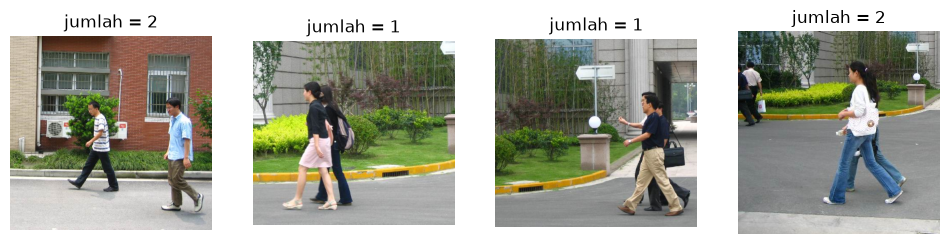

In [4]:
for path in train[PATH_COL][:5]:
    print(path, "ukuran (lebar, tinggi):", Image.open(f"{IMAGE_FOLDER}/{path}").size)

fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, path, count in zip(axes, train[PATH_COL][:4], train[TARGET][:4]):
    ax.imshow(Image.open(f"{IMAGE_FOLDER}/{path}"))
    ax.set_title(f"{TARGET} = {count}")
    ax.axis("off")
plt.show()

## Backbone pretrained beku
Pilih SATU blok: hapus `#` di blok yang ingin dipakai, beri `#` pada blok resnet50.

In [5]:
backbone = models.resnet50(weights=None)
backbone.load_state_dict(torch.load(f"{PRETRAINED}/resnet50/model.pth", map_location="cpu"))
backbone.fc = nn.Identity()

# backbone = models.convnext_tiny(weights=None)
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/convnext_tiny/model.pth",
#                                     map_location="cpu"))
# backbone.classifier[2] = nn.Identity()

# backbone = models.vit_b_16(weights=None)
# backbone.load_state_dict(torch.load(f"{PRETRAINED}/vit_b_16/model.pth", map_location="cpu"))
# backbone.heads = nn.Identity()

backbone = backbone.to(DEVICE)
backbone.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

## Embedding semua gambar

In [6]:
def load_image(path):
    image = Image.open(f"{IMAGE_FOLDER}/{path}").convert("RGB")
    image = image.resize((IMAGE_SIZE, IMAGE_SIZE))
    return (np.asarray(image) / 255 - MEAN) / STD


def embed_images(paths):
    batches = []
    for start in range(0, len(paths), BATCH_SIZE):
        arrays = []
        for path in paths[start:start + BATCH_SIZE]:
            arrays.append(load_image(path))
        batch = torch.tensor(np.stack(arrays), dtype=torch.float32)
        batch = batch.permute(0, 3, 1, 2).to(DEVICE)
        with torch.no_grad():
            batches.append(backbone(batch).cpu())
    return torch.cat(batches).numpy()


X_all = embed_images(list(train[PATH_COL]))
X_test = embed_images(list(test[PATH_COL]))
print("train:", X_all.shape, "| test:", X_test.shape)

train: (120, 2048) | test: (50, 2048)


## Split train / validasi

In [7]:
X_train, X_val, y_train, y_val = train_test_split(X_all, train[TARGET], test_size=0.25,
                                                  random_state=SEED)

## Model
Pilih SATU model: hapus `#` di baris yang ingin dipakai.

In [8]:
model = make_pipeline(StandardScaler(), Ridge(alpha=1000))
# model = make_pipeline(StandardScaler(), Ridge(alpha=100))
# model = make_pipeline(StandardScaler(), SVR(C=3))
# model = KNeighborsRegressor(n_neighbors=5, metric="cosine")
# model = LGBMRegressor(n_estimators=300, learning_rate=0.03, verbose=-1, random_state=SEED)
# model = TransformedTargetRegressor(make_pipeline(StandardScaler(), Ridge(alpha=1000)),
#                                    func=np.log1p, inverse_func=np.expm1)   # target miring

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,2048
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value
"mean_ mean_: ndarray of shape (n_features,) or NoneThe mean value for each feature in the training set.Equal to ``None`` when ``with_mean=False`` and ``with_std=False``.","ndarray[float64](2048,)","[0.08,0. ,0.06,...,0.03,0.03,0.09]"


## Evaluasi di validasi, dibandingkan tebakan rata-rata

MAE model: 0.6972
MAE dibulatkan: 0.6667
MAE tebak rata-rata: 1.0067
RMSE model: 0.8233


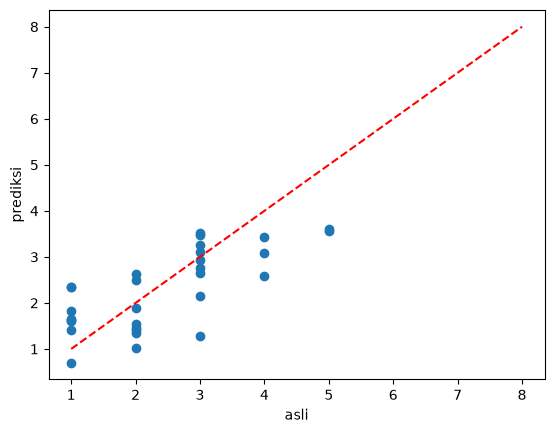

In [9]:
val_predictions = model.predict(X_val)
mean_guess = np.full(len(y_val), y_train.mean())
rounded = np.clip(np.round(val_predictions), 1, None)   # jumlah orang: bulat, minimal 1
print("MAE model:", round(mean_absolute_error(y_val, val_predictions), 4))
print("MAE dibulatkan:", round(mean_absolute_error(y_val, rounded), 4))
print("MAE tebak rata-rata:", round(mean_absolute_error(y_val, mean_guess), 4))
print("RMSE model:", round(root_mean_squared_error(y_val, val_predictions), 4))
plt.scatter(y_val, val_predictions)
plt.plot([1, 8], [1, 8], "r--")
plt.xlabel("asli")
plt.ylabel("prediksi")
plt.show()

## Latih ulang di semua data + submission

In [10]:
model.fit(X_all, train[TARGET])
predictions = model.predict(X_test)

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["jumlah"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,jumlah
0,120,3.645828
1,121,3.994176
2,122,3.275145
3,123,2.333698
4,124,3.598568


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: file kunci hanya ada di data latihan.

In [11]:
test_key = pd.read_csv(TEST_KEY_CSV)["jumlah"]
print("MAE test (kunci latihan):", round(mean_absolute_error(test_key, predictions), 4))

MAE test (kunci latihan): 0.7627
